In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

In [3]:
DATA_DIR = Path.cwd() / "data"
df = pd.read_csv(DATA_DIR / "credit risk_data.csv")
df.head()

,checking_account_status,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_to_income,gender_marital,other_debtors,residence_since,property,age,other_installment_plans,housing,nb_of_existing_credits,job,nb_dependants,telephone,foreing_worker,default
0,... < 0 DM,6,critical account/other credits existing (not at this bank),radio/television,1169,unknown/no savings account,.. >= 7 years,4,male : single,none,4,real estate,67,none,own,2,skilled employee / official,1,"yes, registered under the customers name",yes,0
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,radio/television,5951,... < 100 DM,1 <= ... < 4 years,2,female : divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee / official,1,none,yes,1
2,no checking account,12,critical account/other credits existing (not at this bank),education,2096,... < 100 DM,4 <= ... < 7 years,2,male : single,none,3,real estate,49,none,own,1,unskilled - resident,2,none,yes,0
3,... < 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,... < 100 DM,4 <= ... < 7 years,2,male : single,guarantor,4,building society savings agreement/life insurance,45,none,for free,1,skilled employee / official,2,none,yes,0
4,... < 0 DM,24,delay in paying off in the past,car (new),4870,... < 100 DM,1 <= ... < 4 years,3,male : single,none,4,unknown / no property,53,none,for free,2,skilled employee / official,2,none,yes,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   checking_account_status  1000 non-null   str  
 1   duration_months          1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings_account          1000 non-null   str  
 6   employment_since         1000 non-null   str  
 7   installment_to_income    1000 non-null   int64
 8   gender_marital           1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  residence_since          1000 non-null   int64
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  nb_of_existing_c

In [5]:
df.describe(include='all')

,checking_account_status,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_to_income,gender_marital,other_debtors,residence_since,property,age,other_installment_plans,housing,nb_of_existing_credits,job,nb_dependants,telephone,foreing_worker,default
count,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000.000000,1000,1000.000000,1000,1000,1000.000000
unique,4,NaN,5,10,NaN,5,5,NaN,4,3,NaN,4,NaN,3,3,NaN,4,NaN,2,2,NaN
top,no checking account,NaN,existing credits paid back duly till now,radio/television,NaN,... < 100 DM,1 <= ... < 4 years,NaN,male : single,none,NaN,car or other,NaN,none,own,NaN,skilled employee / official,NaN,none,yes,NaN
freq,394,NaN,530,280,NaN,603,339,NaN,548,907,NaN,332,NaN,814,713,NaN,630,NaN,596,963,NaN
mean,NaN,20.903000,NaN,NaN,3271.258000,NaN,NaN,2.973000,NaN,NaN,2.845000,NaN,35.546000,NaN,NaN,1.407000,NaN,1.155000,NaN,NaN,0.300000
std,NaN,12.058814,NaN,NaN,2822.736876,NaN,NaN,1.118715,NaN,NaN,1.103718,NaN,11.375469,NaN,NaN,0.577654,NaN,0.362086,NaN,NaN,0.458487
min,NaN,4.000000,NaN,NaN,250.000000,NaN,NaN,1.000000,NaN,NaN,1.000000,NaN,19.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,0.000000
25%,NaN,12.000000,NaN,NaN,1365.500000,NaN,NaN,2.000000,NaN,NaN,2.000000,NaN,27.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,0.000000
50%,NaN,18.000000,NaN,NaN,2319.500000,NaN,NaN,3.000000,NaN,NaN,3.000000,NaN,33.000000,NaN,NaN,1.000000,NaN,1.000000,NaN,NaN,0.000000
75%,NaN,24.000000,NaN,NaN,3972.250000,NaN,NaN,4.000000,NaN,NaN,4.000000,NaN,42.000000,NaN,NaN,2.000000,NaN,1.000000,NaN,NaN,1.000000


In [6]:
data_quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique": df.nunique(),
})

print(f"Rows: {len(df):,}; columns: {df.shape[1]}; duplicate rows: {df.duplicated().sum()}")
data_quality

Rows: 1,000; columns: 21; duplicate rows: 0


,dtype,missing,missing_pct,unique
checking_account_status,str,0,0.0,4
duration_months,int64,0,0.0,33
credit_history,str,0,0.0,5
purpose,str,0,0.0,10
credit_amount,int64,0,0.0,921
savings_account,str,0,0.0,5
employment_since,str,0,0.0,5
installment_to_income,int64,0,0.0,4
gender_marital,str,0,0.0,4
other_debtors,str,0,0.0,3


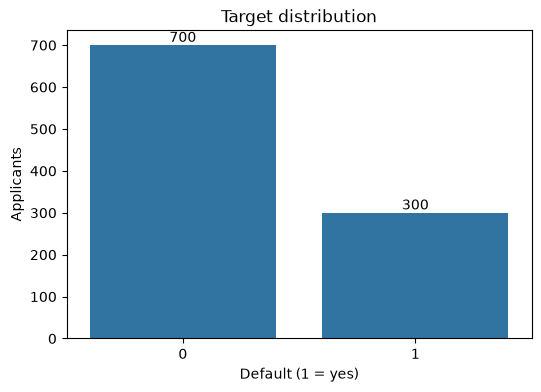

,count,percentage
default,,
0,700,70.0
1,300,30.0


In [7]:
target_distribution = (
    df["default"]
    .value_counts()
    .sort_index()
    .rename_axis("default")
    .to_frame("count")
)
target_distribution["percentage"] = (target_distribution["count"] / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=target_distribution.reset_index(), x="default", y="count", ax=ax)
ax.set(title="Target distribution", xlabel="Default (1 = yes)", ylabel="Applicants")
for container in ax.containers:
    ax.bar_label(container)
plt.show()

target_distribution

# Credit Default Risk Assessment

## Business problem
A lender must decide which applicants can receive credit while controlling losses from borrowers who will default. In this dataset, `default = 1` means the borrower defaulted and `default = 0` means the credit was repaid as agreed.

A **false negative** approves a future defaulter and can create principal, interest, collection, and capital losses. A **false positive** rejects or constrains a reliable borrower and sacrifices revenue and customer value. Because the loss from an undetected default is normally larger, the primary objective is to increase **recall for class 1**, while monitoring precision so that the policy does not reject too many reliable applicants.

## Machine-learning problem
This is supervised binary classification. Given application and credit-history attributes, estimate $P(\mathrm{default}=1\mid X)$ for each applicant.

- **Target:** `default` (1 = default, 0 = no default).
- **Primary model-selection metric:** class-1 recall, subject to acceptable precision.
- **Supporting metrics:** precision, F1, PR-AUC (average precision), ROC-AUC, and confusion matrix.
- **Decision rule:** select the probability threshold using out-of-fold predictions from training data only; evaluate once on the untouched test set.
- **Validation:** stratified cross-validation because only 30% of observations are positive.

PR-AUC is more informative than accuracy under class imbalance, while threshold tuning makes the final classification rule explicit. In production, the threshold should ultimately minimize expected business cost using validated false-negative and false-positive costs.

## Exploratory data analysis

The EDA checks data quality, class imbalance, univariate distributions, association with default, and potentially redundant predictors. Association is descriptive rather than a rule for dropping variables: weak marginal relationships can still contribute through interactions or nonlinear effects.

### Categorical features

For each category, compare both its sample size and observed default rate. Very small groups can produce unstable rates, so they should not be interpreted without their counts.

In [8]:
categorical = df.select_dtypes(include='object').columns.tolist()
categorical

['checking_account_status',
 'credit_history',
 'purpose',
 'savings_account',
 'employment_since',
 'gender_marital',
 'other_debtors',
 'property',
 'other_installment_plans',
 'housing',
 'job',
 'telephone',
 'foreing_worker']

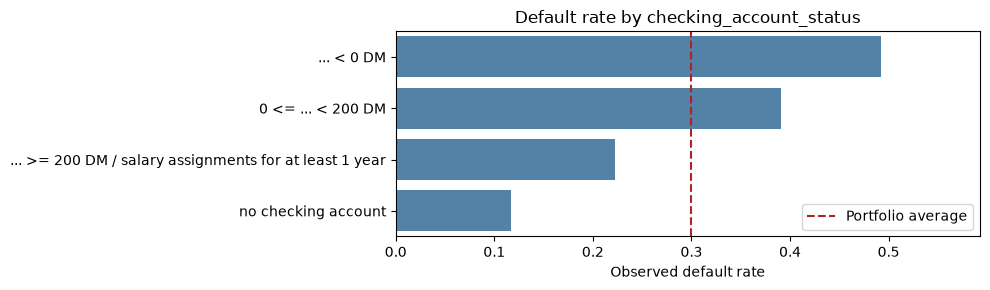

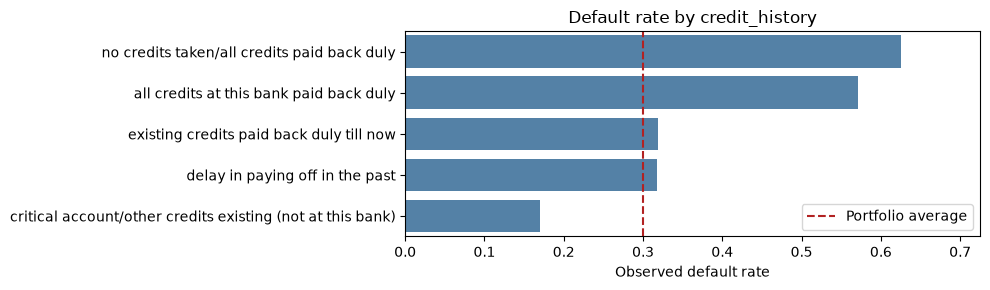

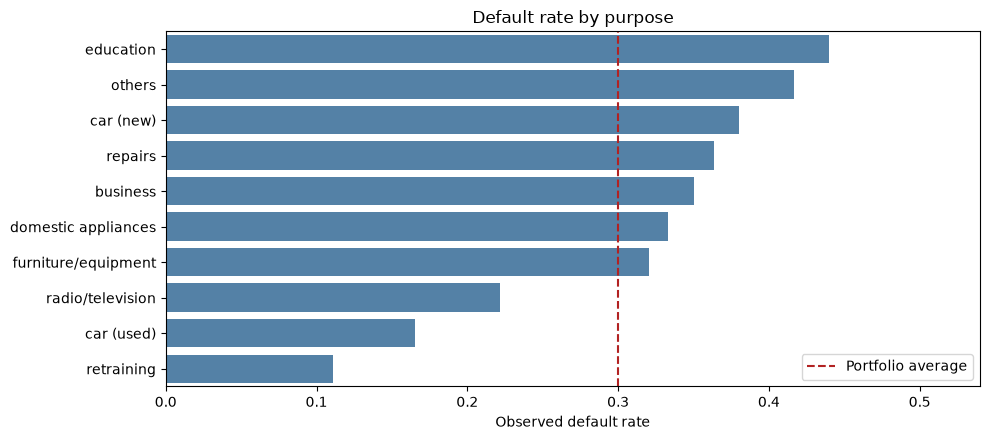

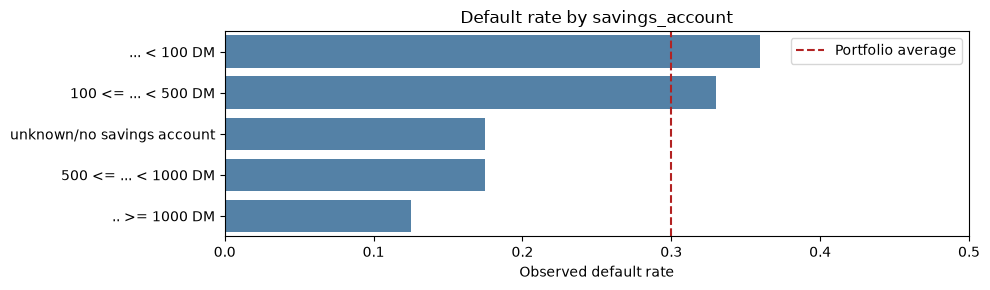

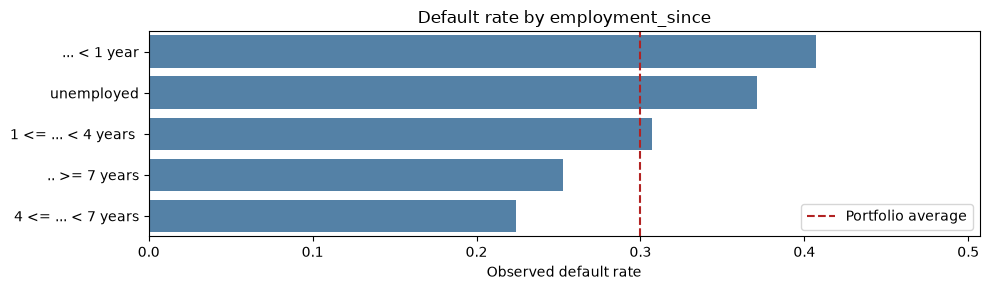

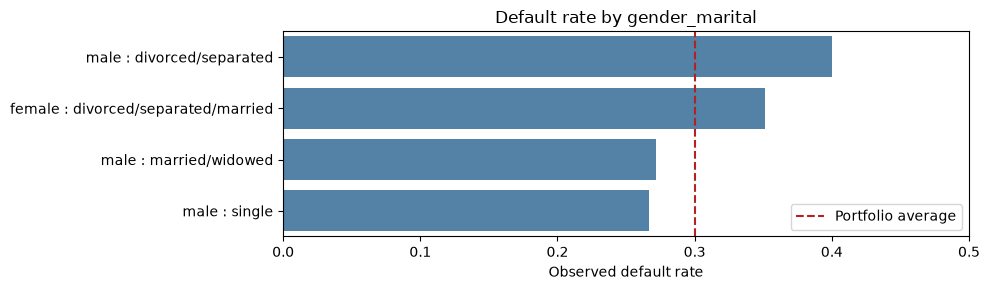

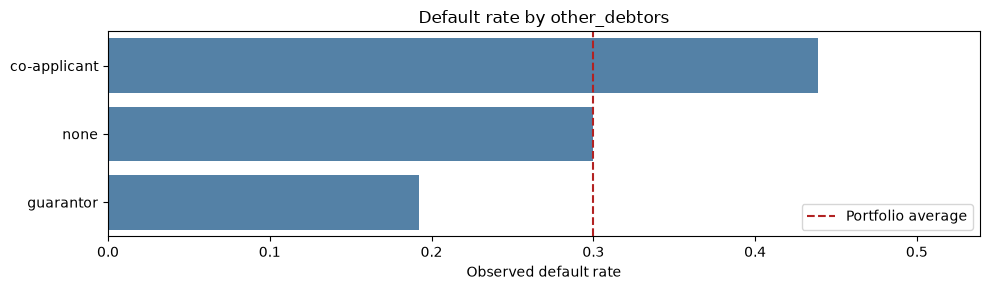

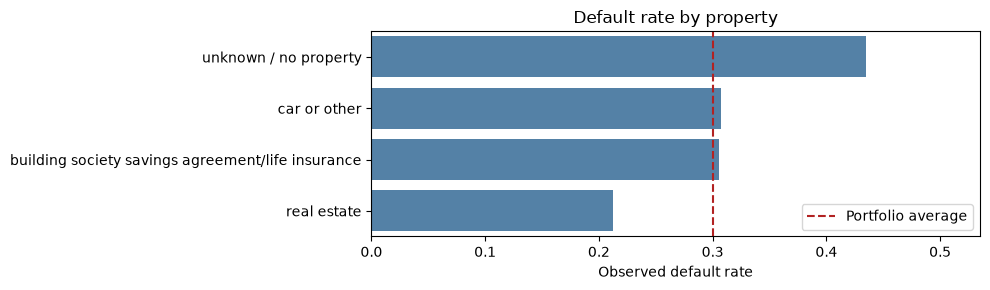

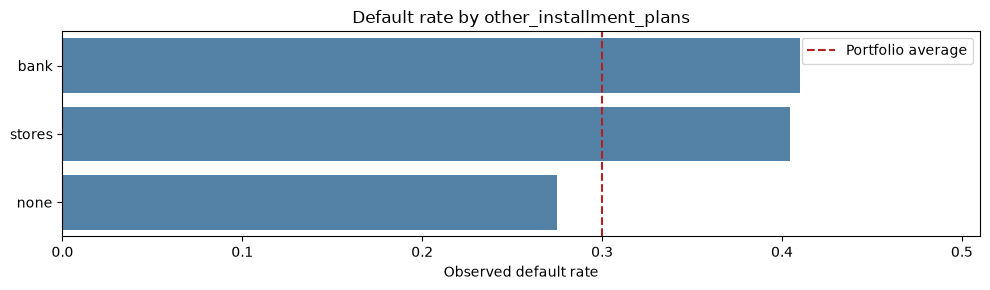

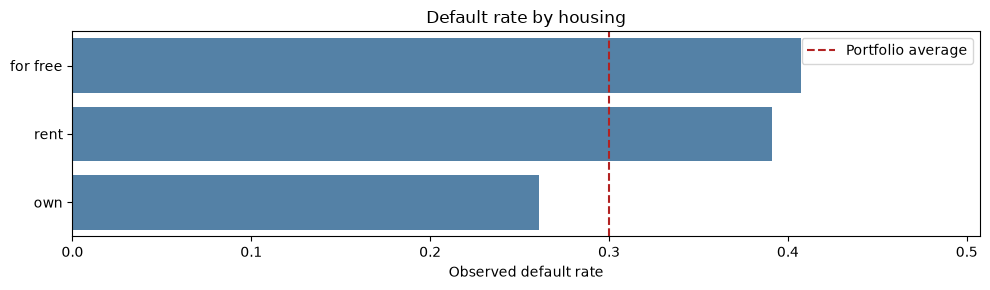

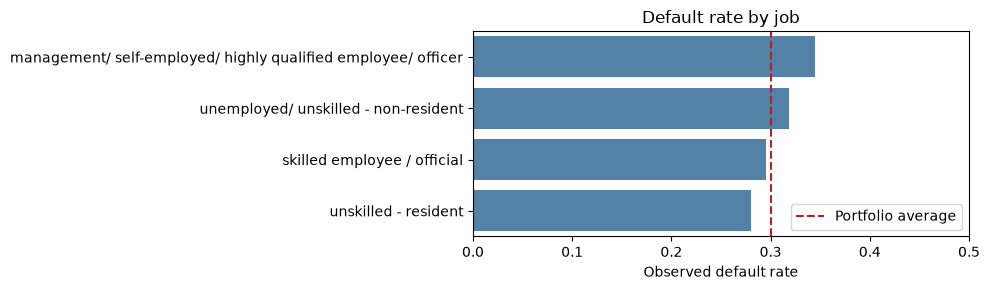

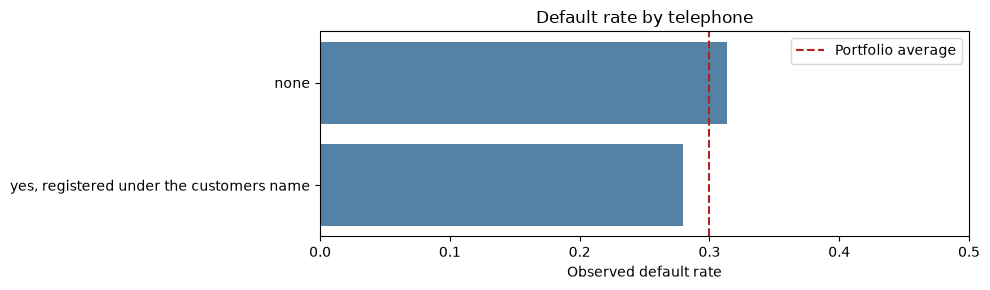

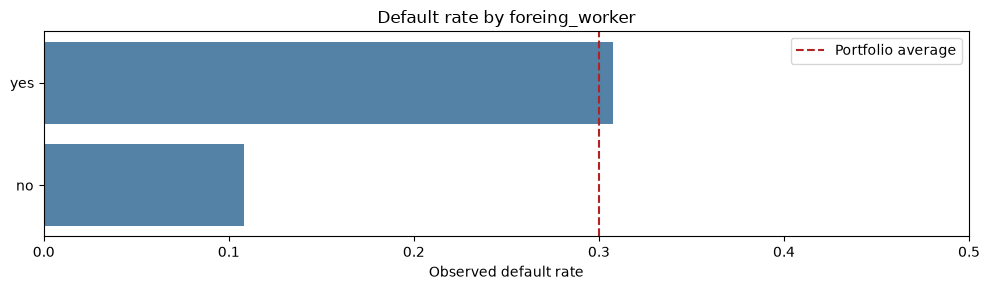

In [9]:
for column in categorical:
    summary = (
        df.groupby(column, observed=True)["default"]
        .agg(default_rate="mean", count="size")
        .sort_values("default_rate", ascending=False)
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * len(summary))))
    sns.barplot(data=summary, y=column, x="default_rate", color="steelblue", ax=ax)
    ax.axvline(df["default"].mean(), color="firebrick", linestyle="--", label="Portfolio average")
    ax.set(title=f"Default rate by {column}", xlabel="Observed default rate", ylabel="")
    ax.set_xlim(0, min(1, max(0.5, summary["default_rate"].max() + 0.1)))
    ax.legend()
    plt.tight_layout()
    plt.show()

In [10]:
from itertools import combinations
from scipy.stats import chi2_contingency


def cramers_v(feature1, feature2):
    table = pd.crosstab(feature1, feature2)
    chi2 = chi2_contingency(table, correction=False)[0]
    sample_size = table.to_numpy().sum()
    denominator = min(table.shape) - 1
    return np.sqrt((chi2 / sample_size) / denominator) if denominator > 0 else 0.0


categorical_target_association = pd.Series(
    {column: cramers_v(df[column], df["default"]) for column in categorical},
    name="cramers_v",
).sort_values(ascending=False)

categorical_pair_association = pd.DataFrame(
    [
        {
            "feature_1": first,
            "feature_2": second,
            "cramers_v": cramers_v(df[first], df[second]),
        }
        for first, second in combinations(categorical, 2)
    ]
).sort_values("cramers_v", ascending=False)

In [11]:
categorical_target_association.to_frame().round(4)

,cramers_v
checking_account_status,0.3517
credit_history,0.2484
savings_account,0.1900
purpose,0.1826
property,0.1540
employment_since,0.1355
housing,0.1349
other_installment_plans,0.1133
gender_marital,0.0980
foreing_worker,0.0821


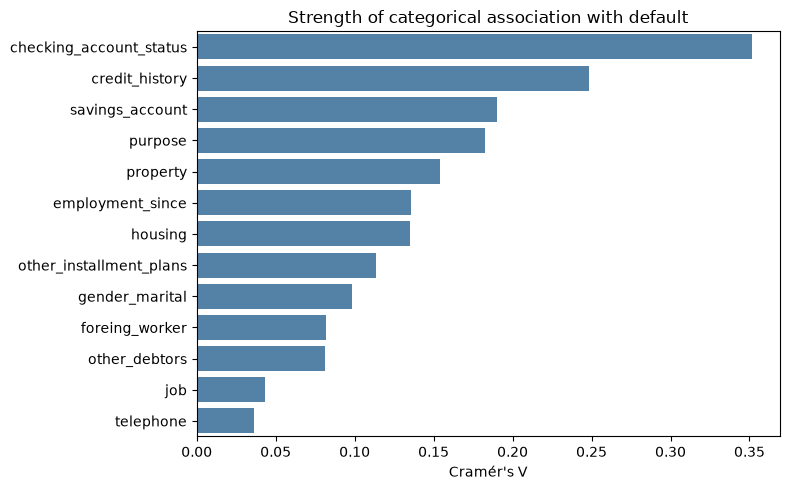

In [12]:
plot_data = (
    categorical_target_association
    .sort_values(ascending=False)
    .rename_axis("feature")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=plot_data,
    x="cramers_v",
    y="feature",
    color="steelblue",
    ax=ax,
)
ax.set(
    title="Strength of categorical association with default",
    xlabel="Cramér's V",
    ylabel="",
)
plt.tight_layout()
plt.show()

### Numerical features

Inspect distributions for skew, outliers, and class separation. Correlations describe linear marginal relationships only; they do not prove causality or capture nonlinear interactions.

In [13]:
numerical = df.select_dtypes(include="number").columns.drop("default").tolist()
numerical

['duration_months',
 'credit_amount',
 'installment_to_income',
 'residence_since',
 'age',
 'nb_of_existing_credits',
 'nb_dependants']

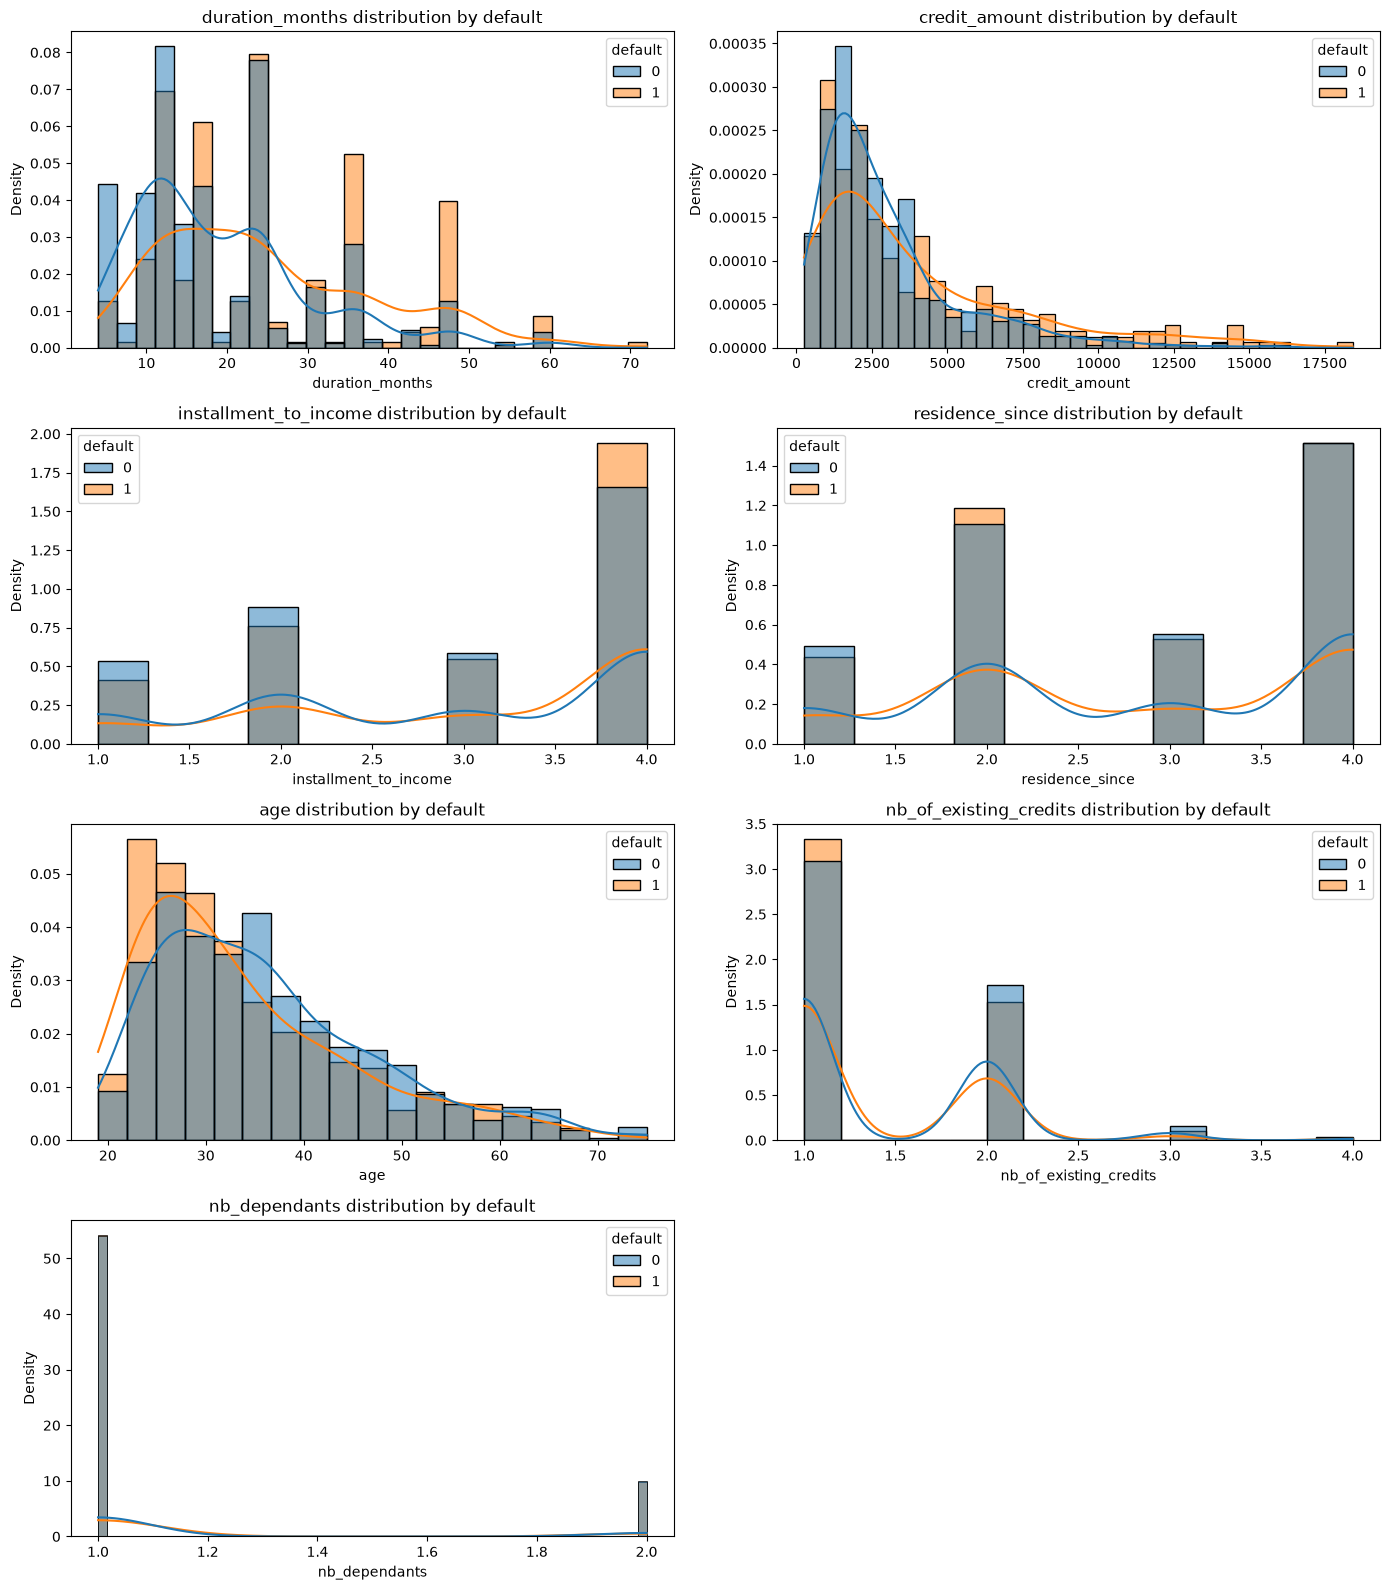

In [14]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for column, ax in zip(numerical, axes.flat):
    sns.histplot(data=df, x=column, hue="default", stat="density", common_norm=False, kde=True, ax=ax)
    ax.set_title(f"{column} distribution by default")
for ax in axes.flat[len(numerical):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

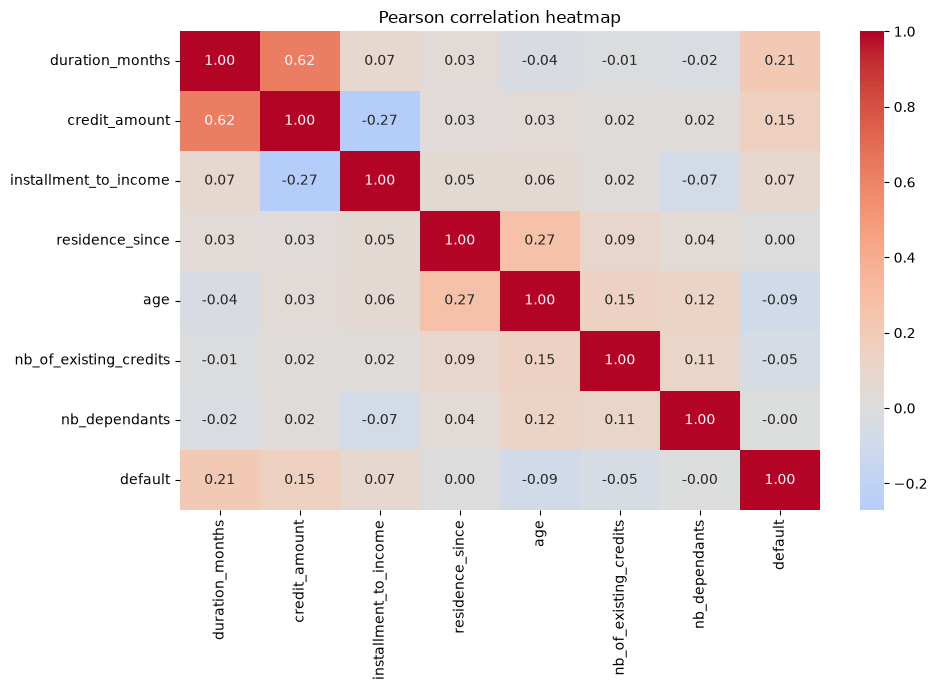

In [15]:
corr = df[numerical + ["default"]].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Pearson correlation heatmap")
plt.tight_layout()
plt.show()

### EDA conclusions

- The target is moderately imbalanced: defaults are the minority class, so accuracy alone would hide costly missed defaults.
- Cramér's V measures the strength of categorical association with default. Checking-account status and credit history have the strongest marginal categorical associations.
- Duration and credit amount typically show the clearest numerical relationship with default. Their association is not strong enough to justify univariate feature selection.
- Correlated predictors are retained. Regularized logistic regression stabilizes coefficients, while XGBoost can use nonlinearities and interactions.
- EDA uses the complete dataset only for descriptive understanding. All preprocessing, hyperparameter selection, and threshold selection below are fit using training data only.

## Modeling strategy

We compare an interpretable regularized logistic regression with a nonlinear XGBoost model. Hyperparameters are selected by cross-validated average precision (PR-AUC), which evaluates probability ranking without fixing a threshold. The operating threshold is then selected from out-of-fold training predictions by maximizing $F_2$, which assigns recall twice the importance of precision.

This reflects the stated business asymmetry: missing a defaulter is generally more expensive than reviewing or declining a reliable applicant. Precision, confusion matrices, and the number of false positives remain visible to guard against an unusable policy.

In [16]:
from sklearn.model_selection import StratifiedKFold, train_test_split

X = df.drop(columns="default")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Training observations: {len(X_train)}; test observations: {len(X_test)}")
print(f"Training default rate: {y_train.mean():.1%}; test default rate: {y_test.mean():.1%}")

Training observations: 800; test observations: 200
Training default rate: 30.0%; test default rate: 30.0%


In [17]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)


def select_f2_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    f2_scores = (1+2**2) * precision[:-1] * recall[:-1] / (2**2 * precision[:-1] + recall[:-1] + 1e-12)
    best_index = np.argmax(f2_scores)
    return float(thresholds[best_index]), float(f2_scores[best_index])


def evaluate_classifier(name, y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "model": name,
        "threshold": threshold,
        "average_precision": average_precision_score(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "precision_default": precision_score(y_true, predictions),
        "recall_default": recall_score(y_true, predictions),
        "f1_default": f1_score(y_true, predictions),
        "f2_default": fbeta_score(y_true, predictions, beta=2),
    }, predictions

In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    solver="liblinear",
    max_iter=2_000,
    random_state=42,
)

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), categorical),
    ]
)

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", logistic_model),
    ]
)

In [20]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV

logistic_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid={
        "model__C": np.logspace(-3, 2, 8),
        "model__penalty": ["l1", "l2"],
        "model__class_weight": [None, "balanced"],
    },
    scoring={
        "average_precision": "average_precision",
        "recall": "recall",
        "f2": make_scorer(fbeta_score, beta=2),
    },
    refit="average_precision",
    cv=cv,
    n_jobs=-1,
)
logistic_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': array([1.0000...00000000e+02]), 'model__class_weight': [None, 'balanced'], 'model__penalty': ['l1', 'l2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'average_precision': 'average_precision', 'f2': make_scorer(f...dict', beta=2), 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'average_precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can 

In [21]:
print("Best logistic parameters:", logistic_search.best_params_)
print(f"Best CV average precision: {logistic_search.best_score_:.3f}")

Best logistic parameters: {'model__C': np.float64(0.13894954943731375), 'model__class_weight': None, 'model__penalty': 'l2'}
Best CV average precision: 0.612


In [22]:
def plot_precision_recall_curves(y_true, model_probabilities):
    baseline = y_true.mean()
    fig, ax = plt.subplots(figsize=(8, 5))
    for name, probabilities in model_probabilities.items():
        precision, recall, _ = precision_recall_curve(y_true, probabilities)
        average_precision = average_precision_score(y_true, probabilities)
        ax.plot(recall, precision, label=f"{name} (AP={average_precision:.3f})")
    ax.axhline(baseline, color="grey", linestyle="--", label=f"No-skill ({baseline:.2f})")
    ax.set(xlabel="Recall for default", ylabel="Precision for default", title="Test precision-recall curves")
    ax.legend()
    plt.show()

### Logistic regression: validation and threshold selection

The best regularized model is selected by cross-validated average precision. Its classification threshold is selected separately from out-of-fold training probabilities, preventing the test labels from influencing the operating policy.

In [23]:
from sklearn.model_selection import cross_val_predict

logistic_best = logistic_search.best_estimator_
logistic_oof_probability = cross_val_predict(
    logistic_best,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
logistic_threshold, logistic_oof_f2 = select_f2_threshold(y_train, logistic_oof_probability)

print(f"OOF-selected logistic threshold: {logistic_threshold:.3f}")
print(f"OOF F2 at selected threshold: {logistic_oof_f2:.3f}")

OOF-selected logistic threshold: 0.168
OOF F2 at selected threshold: 0.737


In [24]:
logistic_best.fit(X_train, y_train)
logistic_test_probability = logistic_best.predict_proba(X_test)[:, 1]
logistic_metrics, logistic_test_prediction = evaluate_classifier(
    "Logistic regression",
    y_test,
    logistic_test_probability,
    logistic_threshold,
)

              precision    recall  f1-score   support

           0      0.900     0.450     0.600       140
           1      0.408     0.883     0.558        60

    accuracy                          0.580       200
   macro avg      0.654     0.667     0.579       200
weighted avg      0.752     0.580     0.587       200



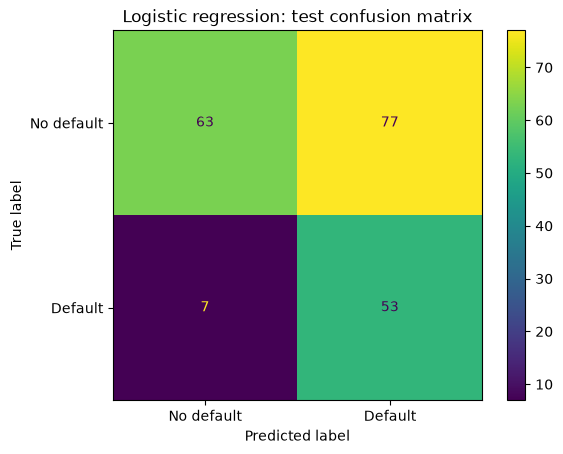

In [25]:
print(classification_report(y_test, logistic_test_prediction, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, logistic_test_prediction, display_labels=["No default", "Default"])
plt.title("Logistic regression: test confusion matrix")
plt.show()

In [26]:
model_metrics = [logistic_metrics]
pd.DataFrame(model_metrics).set_index("model").round(3)

,threshold,average_precision,roc_auc,precision_default,recall_default,f1_default,f2_default
model,,,,,,,
Logistic regression,0.168,0.661,0.802,0.408,0.883,0.558,0.716


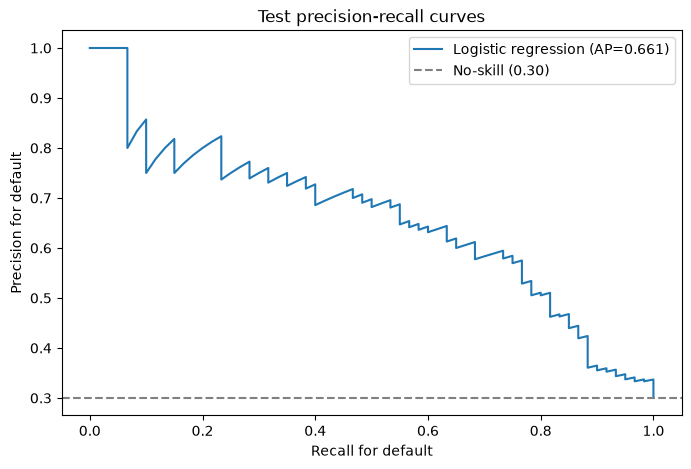

In [27]:
plot_precision_recall_curves(
    y_test,
    {"Logistic regression": logistic_test_probability},
)

### XGBoost optimization with Optuna

Optuna uses a seeded TPE sampler to search a continuous and conditional-friendly hyperparameter space more efficiently than a Cartesian grid. Each trial is scored by mean stratified-CV average precision on training data. `scale_pos_weight` is tuned as a scalar around the training-set negative-to-positive ratio; it is not an array of per-class weights.

In [29]:
import optuna
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
imbalance_ratio = negative_count / positive_count
print(f"Training negative/positive ratio: {imbalance_ratio:.3f}")

optuna.logging.set_verbosity(optuna.logging.WARNING)

Training negative/positive ratio: 2.333


In [30]:
def xgb_objective(trial):
    model = XGBClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
        max_depth=trial.suggest_int("max_depth", 2, 8),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.30, log=True),
        min_child_weight=trial.suggest_float("min_child_weight", 1.0, 12.0),
        subsample=trial.suggest_float("subsample", 0.60, 1.00),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.60, 1.00),
        gamma=trial.suggest_float("gamma", 0.0, 5.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 1.0, imbalance_ratio * 2),
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )
    candidate = Pipeline([("preprocessor", preprocessor), ("model", model)])
    return cross_val_score(
        candidate,
        X_train,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=-1,
    ).mean()

In [31]:
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
)
study.optimize(xgb_objective, n_trials=30, show_progress_bar=True)

print(f"Best CV average precision: {study.best_value:.3f}")
pd.Series(study.best_params, name="best_value")

  0%|          | 0/30 [00:00<?, ?it/s]

Best trial: 28. Best value: 0.638439: 100%|██████████| 30/30 [00:44<00:00,  1.47s/it]

Best CV average precision: 0.638


n_estimators        550.000000
max_depth             4.000000
learning_rate         0.093266
min_child_weight      3.802050
subsample             0.698053
colsample_bytree      0.681620
gamma                 2.305713
reg_alpha             2.587718
reg_lambda            3.209834
scale_pos_weight      2.919723
Name: best_value, dtype: float64

In [32]:
xgb_model = XGBClassifier(
    **study.best_params,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)
xgb_best = Pipeline([("preprocessor", preprocessor), ("model", xgb_model)])

In [33]:
xgb_oof_probability = cross_val_predict(
    xgb_best,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
xgb_threshold, xgb_oof_f2 = select_f2_threshold(y_train, xgb_oof_probability)

print(f"OOF-selected XGBoost threshold: {xgb_threshold:.3f}")
print(f"OOF F2 at selected threshold: {xgb_oof_f2:.3f}")

OOF-selected XGBoost threshold: 0.352
OOF F2 at selected threshold: 0.737


              precision    recall  f1-score   support

           0      0.855     0.507     0.637       140
           1      0.410     0.800     0.542        60

    accuracy                          0.595       200
   macro avg      0.633     0.654     0.590       200
weighted avg      0.722     0.595     0.608       200



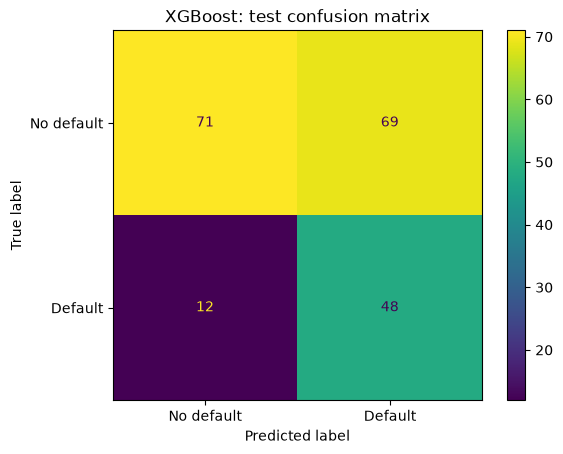

In [34]:
xgb_best.fit(X_train, y_train)
xgb_test_probability = xgb_best.predict_proba(X_test)[:, 1]
xgb_metrics, xgb_test_prediction = evaluate_classifier(
    "XGBoost",
    y_test,
    xgb_test_probability,
    xgb_threshold,
)

print(classification_report(y_test, xgb_test_prediction, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, xgb_test_prediction, display_labels=["No default", "Default"])
plt.title("XGBoost: test confusion matrix")
plt.show()

In [35]:
model_metrics.append(xgb_metrics)
comparison = pd.DataFrame(model_metrics).set_index("model").sort_values("average_precision", ascending=False)
comparison.round(3)

,threshold,average_precision,roc_auc,precision_default,recall_default,f1_default,f2_default
model,,,,,,,
Logistic regression,0.168,0.661,0.802,0.408,0.883,0.558,0.716
XGBoost,0.352,0.633,0.767,0.410,0.800,0.542,0.672


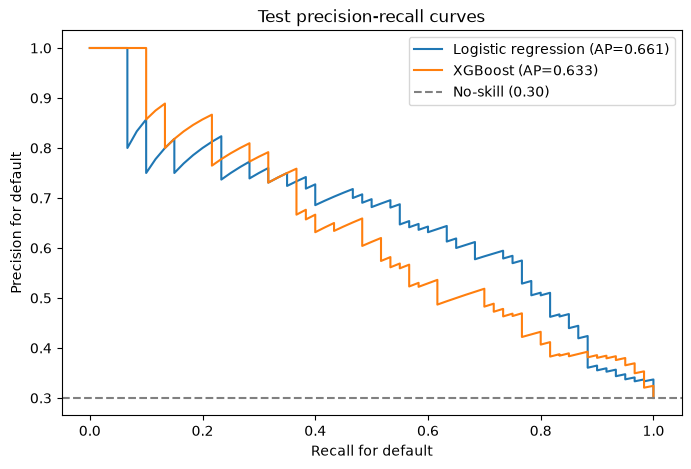

In [36]:
plot_precision_recall_curves(
    y_test,
    {
        "Logistic regression": logistic_test_probability,
        "XGBoost": xgb_test_probability,
    },
)

## Model explainability

### Global importance with SHAP

SHAP attributes each XGBoost prediction to transformed features. Mean absolute SHAP values provide global importance, while the beeswarm plot also shows effect direction and variation. These are predictive associations, not causal effects.

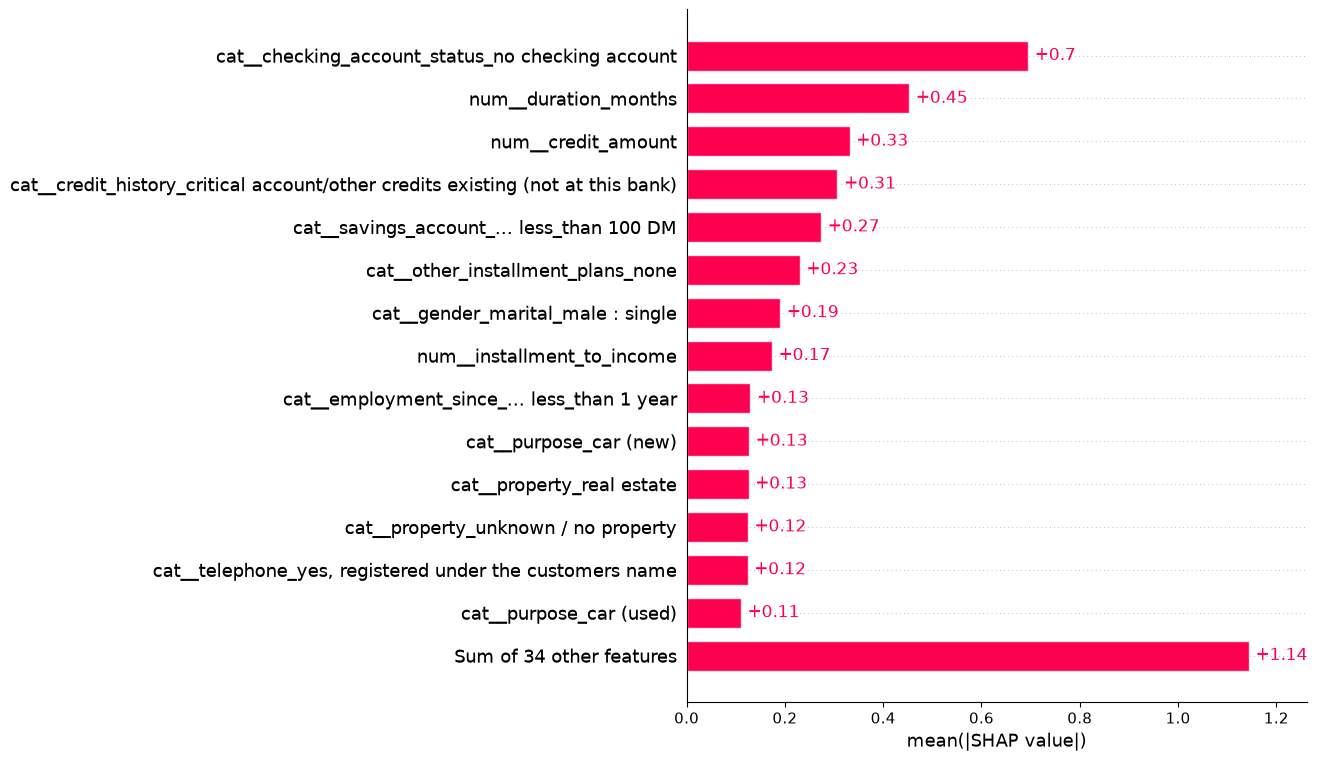

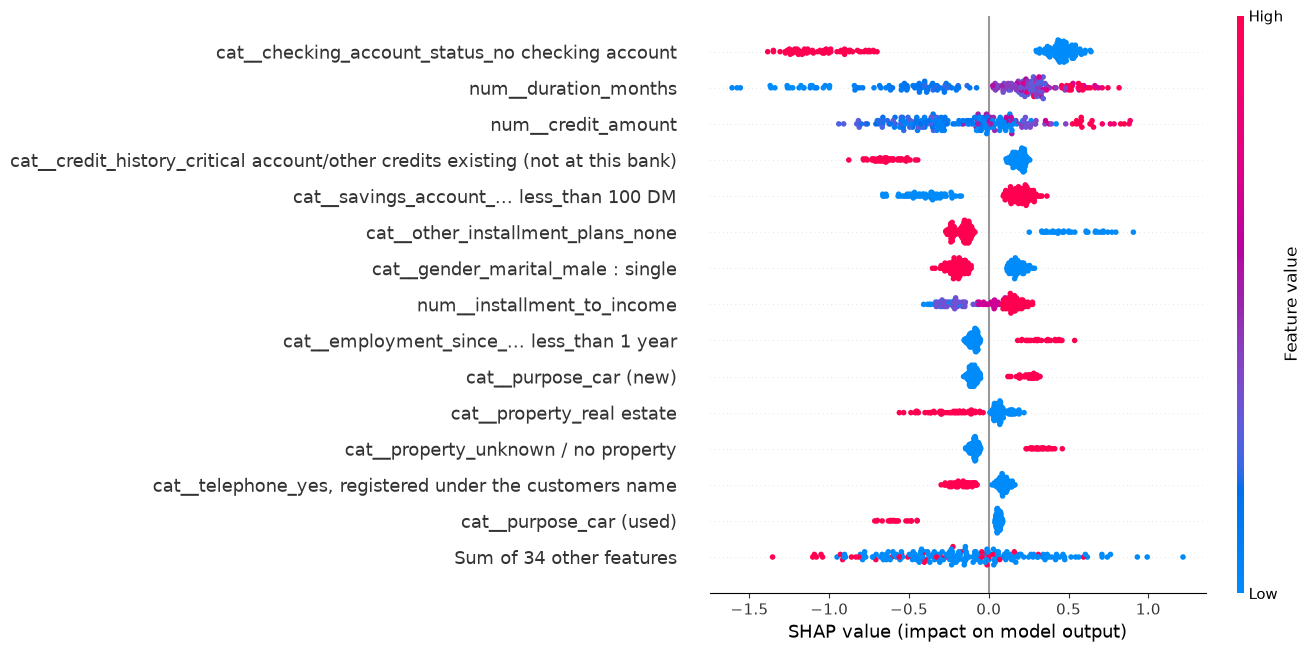

In [37]:
import shap

fitted_preprocessor = xgb_best.named_steps["preprocessor"]
fitted_xgb = xgb_best.named_steps["model"]
feature_names = [
    name.replace("[", "(").replace("]", ")").replace("<", "less_than")
    for name in fitted_preprocessor.get_feature_names_out()
]

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)
if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()
    X_test_transformed = X_test_transformed.toarray()

X_train_explain = pd.DataFrame(X_train_transformed, columns=feature_names, index=X_train.index)
X_test_explain = pd.DataFrame(X_test_transformed, columns=feature_names, index=X_test.index)

shap_explainer = shap.TreeExplainer(fitted_xgb)
shap_values = shap_explainer(X_test_explain)

shap.plots.bar(shap_values, max_display=15)
shap.plots.beeswarm(shap_values, max_display=15)

### Local explanation with LIME

LIME fits a simple surrogate around one transformed applicant. The following example explains the applicant with the highest predicted default probability in the test set. LIME weights are local and must not be interpreted as global feature importance.

In [39]:
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_explain.to_numpy(),
    feature_names=feature_names,
    class_names=["No default", "Default"],
    mode="classification",
    discretize_continuous=True,
    random_state=42,
)

highest_risk_position = int(np.argmax(xgb_test_probability))
lime_explanation = lime_explainer.explain_instance(
    X_test_explain.iloc[highest_risk_position].to_numpy(),
    fitted_xgb.predict_proba,
    num_features=12,
)

print(f"Explained test index: {X_test_explain.index[highest_risk_position]}")
print(f"Predicted default probability: {xgb_test_probability[highest_risk_position]:.3f}")
lime_importance = pd.DataFrame(lime_explanation.as_list(), columns=["local_condition", "weight"])
lime_importance

Explained test index: 11
Predicted default probability: 0.967


,local_condition,weight
0,num__duration_months > 0.27,0.170499
1,cat__checking_account_status_no checking account <= 0.00,0.168765
2,cat__credit_history_critical account/other credits existing (not at this bank) <= 0.00,0.135529
3,cat__purpose_car (used) <= 0.00,0.123531
4,cat__purpose_education <= 0.00,-0.122695
5,0.00 < cat__savings_account_... less_than 100 DM <= 1.00,0.116742
6,num__credit_amount > 0.28,0.104250
7,cat__employment_since_4 less_than= ... less_than 7 years <= 0.00,0.087471
8,cat__property_unknown / no property <= 0.00,-0.077240
9,cat__purpose_car (new) <= 0.00,-0.072842


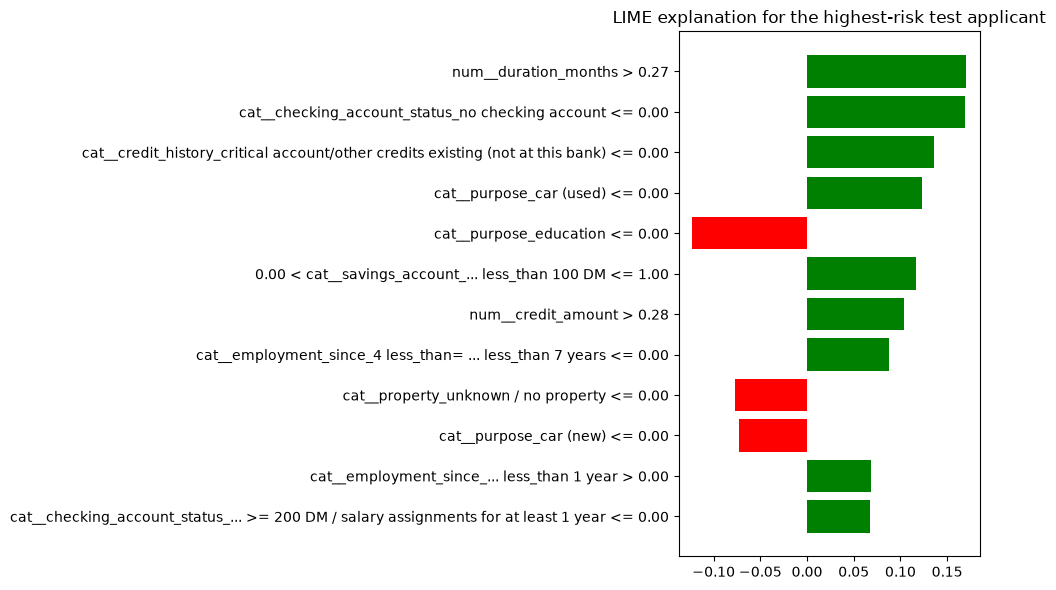

In [40]:
fig = lime_explanation.as_pyplot_figure()
fig.set_size_inches(10, 6)
plt.title("LIME explanation for the highest-risk test applicant")
plt.tight_layout()
plt.show()

## Conclusions

- Model selection is based on probability-ranking quality (cross-validated average precision), while the operating threshold is selected independently with recall-weighted $F_2$ on out-of-fold training predictions.
- The final test comparison reports recall and precision for defaulters together. A model should not be chosen from accuracy alone, and the test set must not be reused for threshold tuning.
- SHAP supplies global and per-applicant XGBoost attributions; LIME supplies a local surrogate explanation for one applicant. Neither method establishes causality.
- Before deployment, replace the generic $F_2$ preference with an expected-cost threshold based on actual default loss, review cost, approval revenue, and lending-policy constraints.
- Validate probability calibration, temporal stability, subgroup fairness, and explanation stability on recent out-of-time data. This dataset is small, so reported test differences have substantial sampling uncertainty.